<a href="https://colab.research.google.com/github/Mihret4204/math4ai/blob/main/Mihret_Shewarega_Math_for_AI_lab_2_2019.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# 🧮 Lab 2: Applications of Linear Algebra in AI

**Course:** Mathematics for Artificial Intelligence  
**Lab Focus:** Data Representation, Matrix Operations, and Practical AI Applications  
**Tools:** Python, NumPy, Pandas, Matplotlib, Scikit-learn, and Scikit-image

---

## Introduction

Linear algebra provides the mathematical foundation for representing and manipulating data in artificial intelligence. Many types of data, including numerical measurements, images, audio, and text, can be represented using vectors, matrices, and multidimensional arrays.

In this lab, we will explore how fundamental linear algebra concepts are applied to real-world datasets and digital images using Python.

Rather than working only with abstract mathematical expressions, we will examine how data is stored numerically and how operations such as indexing, scalar multiplication, matrix addition, and vector dot products are used in practical applications.

## Lab Activities

### 🌸 Activity 1: Tabular Data as Vectors and Matrices

We will explore how structured datasets are represented using vectors and matrices, using the **Iris dataset** as our main example.

Students will learn to:

1. Load and explore a real-world dataset.
2. Represent observations as vectors and datasets as matrices.
3. Identify rows, columns, features, and target labels.
4. Examine matrix dimensions and individual elements.
5. Access and manipulate data using NumPy indexing and slicing.

### 🖼️ Activity 2: Images as Matrices and Applications of Linear Algebra

We will investigate how digital images are represented numerically and how basic linear algebra operations can be used for image processing.

Students will learn to:

1. Represent grayscale and RGB images as numerical arrays.
2. Extract color channels and inspect pixel values.
3. Adjust image brightness using scalar operations.
4. Flip and blend images using array operations.
5. Convert RGB images to grayscale using vector dot products.
6. Understand image transparency and RGBA representation.
7. Remove image backgrounds using color-based masks.
8. Replace image backgrounds using alpha compositing.

## Learning Outcomes

By the end of this lab, students should be able to:

- Explain how structured datasets and digital images are represented using vectors, matrices, and multidimensional arrays.
- Identify the dimensions, shapes, and elements of numerical arrays.
- Apply NumPy indexing and slicing to extract and manipulate data.
- Perform basic linear algebra operations on real-world data.
- Explain how matrix and vector operations support practical image-processing tasks.
- Connect fundamental linear algebra concepts to applications in artificial intelligence and computer vision.

## Lab Requirements

- **Environment:** Google Colab
- **Programming language:** Python
- **Libraries:** NumPy, Pandas, Matplotlib, Scikit-learn, Scikit-image, and Pillow
- **Prerequisites:** Basic Python programming and introductory knowledge of vectors and matrices

**Instructions:** Follow each activity step by step, execute the provided code cells, examine the outputs, and complete the exercises at the end of each activity.


In [ ]:

#@title Setup and Utility Functions { display-mode: "form" }

# Import NumPy for numerical arrays and matrix operations.
import numpy as np

# Import Pandas for tabular data representation and manipulation.
import pandas as pd

# Import Matplotlib for plotting and displaying images.
import matplotlib.pyplot as plt

# Import SymPy for displaying matrices in mathematical notation.
from sympy import Matrix, latex

# Import display tools for formatted mathematical output.
from IPython.display import display, Math

# Import the Iris dataset for tabular-data examples.
from sklearn.datasets import load_iris

# Import logistic regression for the classification application.
from sklearn.linear_model import LogisticRegression

# Import sample images from scikit-image.
from skimage import data

# Display floating-point values with three decimal places.
# Suppress scientific notation for small values when practical.
# This changes only how values are displayed, not their precision.
np.set_printoptions(precision=3, suppress=True)


# ------------------------------------------------------------
# Utility Function 1: Display a Matrix
# ------------------------------------------------------------

def show_matrix(A, name="A"):
    """Display a matrix using mathematical notation."""

    display(Math(name + " = " + latex(Matrix(A))))
    print()


# ------------------------------------------------------------
# Utility Function 2: Display a Single Image
# ------------------------------------------------------------

def show_image(image, title="", cmap=None):
    """Display a single image with an optional title and colormap."""

    plt.figure(figsize=(5, 4))

    plt.imshow(image, cmap=cmap)

    plt.title(title)

    plt.axis("off")

    plt.show()


# ------------------------------------------------------------
# Utility Function 3: Compare Multiple Images
# ------------------------------------------------------------

def compare_images(images, titles, cmaps=None):
    """Display multiple images side by side for comparison."""

    n = len(images)

    if n == 0:
        raise ValueError("Provide at least one image.")

    if len(titles) != n:
        raise ValueError("Images and titles must have the same length.")

    if cmaps is None:
        cmaps = [None] * n

    if len(cmaps) != n:
        raise ValueError("Images and colormaps must have the same length.")

    fig, axes = plt.subplots(1, n, figsize=(5 * n, 4))

    if n == 1:
        axes = [axes]

    for ax, image, title, cmap in zip(
        axes, images, titles, cmaps
    ):
        ax.imshow(image, cmap=cmap)

        ax.set_title(title)

        ax.axis("off")

    plt.tight_layout()

    plt.show()


## Activity 1: Tabular Data Representation Using the Iris Dataset

In this activity, we will explore how real-world tabular data can be represented mathematically using **matrices and vectors**. We will use the Iris dataset, which contains 150 flower observations belonging to three species: Setosa, Versicolor, and Virginica. Each observation has four numerical features: sepal length, sepal width, petal length, and petal width.

Using Python, we will:

1. Load the Iris dataset and organize it into a Pandas DataFrame.
2. Display sample observations from all three flower species.
3. Examine the dataset dimensions, feature names, and class labels.
4. Represent the numerical features as a matrix \(X\) and the class labels as a vector \(y\).
5. Access individual matrix elements, rows, and columns using NumPy.

**Learning objective:** Understand how tabular datasets are organized as matrices, where rows represent observations, columns represent features, and target vectors contain the corresponding labels.

In [ ]:
# ------------------------------------------------------------
# Step 1: Load the Iris Dataset
# ------------------------------------------------------------

# Load the built-in Iris flower dataset.
iris = load_iris()

# Extract the feature values and target labels.
X = iris.data
y = iris.target

# Extract the feature names and flower species names.
feature_names = iris.feature_names
class_names = iris.target_names

In [ ]:
# ------------------------------------------------------------
# Step 2: Create a Pandas DataFrame
# ------------------------------------------------------------

# Convert the feature matrix into a labeled table.
df = pd.DataFrame(X, columns=feature_names)

# Add the corresponding flower species to each observation.
df["species"] = [class_names[label] for label in y]


# ------------------------------------------------------------
# Display Sample Observations from All Three Classes
# ------------------------------------------------------------

# Display the first five observations (Setosa).
print("First five observations (Setosa):")
display(df.head(5))

# Display five observations from the second class (Versicolor).
print("\nObservations 50–54 (Versicolor):")
display(df.iloc[50:55])

# Display the last five observations (Virginica).
print("\nLast five observations (Virginica):")
display(df.tail(5))



First five observations (Setosa):


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Observations 50–54 (Versicolor):


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
50,7.0,3.2,4.7,1.4,versicolor
51,6.4,3.2,4.5,1.5,versicolor
52,6.9,3.1,4.9,1.5,versicolor
53,5.5,2.3,4.0,1.3,versicolor
54,6.5,2.8,4.6,1.5,versicolor



Last five observations (Virginica):


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica
149,5.9,3.0,5.1,1.8,virginica


In [ ]:
# ------------------------------------------------------------
# Step 3: Examine the Dataset Structure
# ------------------------------------------------------------

print("\nDataset information:")
print("Number of observations:", X.shape[0])
print("Number of features:", X.shape[1])
print("Shape of feature matrix X:", X.shape)
print("Shape of target vector y:", y.shape)

print("\nFeature names:", feature_names)
print("\nFlower species:", class_names)



Dataset information:
Number of observations: 150
Number of features: 4
Shape of feature matrix X: (150, 4)
Shape of target vector y: (150,)

Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Flower species: ['setosa' 'versicolor' 'virginica']


In [ ]:
# ------------------------------------------------------------
# Step 4: Represent Tabular Data as a Matrix
# ------------------------------------------------------------

# Select the first five observations.
X_small = X[:5, :]

print("\nFirst five observations as a NumPy array:")
print(X_small)
print()

# Display the same data in mathematical matrix notation.
show_matrix(X_small, "X")


First five observations as a NumPy array:
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]



<IPython.core.display.Math object>

In [ ]:
# ------------------------------------------------------------
# Step 5: Access Rows, Columns, and Individual Elements
# ------------------------------------------------------------

# First row: all feature measurements of the first flower.
print("First observation:")
print(X[0, :])

# First column: sepal length of the first five flowers.
print("\nFirst feature (first five observations):")
print(X[:5, 0])

# Individual element: second feature of the first observation.
print("\nElement X[0, 1]:")
print(X[0, 1])

First observation:
[5.1 3.5 1.4 0.2]

First feature (first five observations):
[5.1 4.9 4.7 4.6 5. ]

Element X[0, 1]:
3.5


In [ ]:
# ------------------------------------------------------------
# Step 6: Examine the Target Vector
# ------------------------------------------------------------

print("\nFirst ten target labels:")
print(y[:10])

print("\nCorresponding flower species:")
print(class_names[y[:10]])
print()

# Display the first ten target labels as a column vector.
show_matrix(y[:10].reshape(-1, 1), "y")


First ten target labels:
[0 0 0 0 0 0 0 0 0 0]

Corresponding flower species:
['setosa' 'setosa' 'setosa' 'setosa' 'setosa' 'setosa' 'setosa' 'setosa'
 'setosa' 'setosa']



<IPython.core.display.Math object>

### **Exercise 1**: Loading and Exploring a CSV Dataset

**Objective:** Practice loading a real-world CSV dataset, examining its structure, and representing numerical data using matrices and vectors.

In this exercise, you will work with the **Palmer Penguins dataset**, which contains physical measurements of three penguin species.

**Dataset URL:**

https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv

#### Instructions

**Step 1: Load the dataset**

- Use the Pandas function `pd.read_csv()` to load the dataset directly from the URL.
- Store the resulting DataFrame in a variable named `penguins`.

**Step 2: Explore the dataset**

- Use `head()` to display the first five observations.
- Use `tail()` to display the last five observations.
- Use `sample(5)` to display five randomly selected observations.

**Step 3: Examine the dataset structure**

- Use `shape` to determine the number of observations and columns.
- Use `columns` to display the column names.
- Use `info()` to examine data types and non-missing values.
- Use `isnull().sum()` to identify missing values in each column.

**Step 4: Explore the penguin species**

- Use `value_counts()` on the `species` column to determine how many observations belong to each species.
- Display the first five observations belonging to each species.

**Step 5: Represent the dataset as a matrix**

- Select the four numerical measurement columns: `bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, and `body_mass_g`.
- Remove rows containing missing values in these selected columns using `dropna()`.
- Convert the resulting DataFrame into a NumPy array using `to_numpy()`.
- Store the matrix in a variable named `X`.

**Step 6: Perform basic matrix operations**

- Display the dimensions of `X`.
- Extract and display the first five rows.
- Extract the first column.
- Extract the feature vector of the tenth observation.
- Access the element in the third row and second column.

**Expected outcome:** By completing this exercise, you should be able to load a CSV dataset, explore its contents, identify missing values, and represent numerical tabular data as a matrix suitable for further mathematical operations.

In [ ]:

#@title Download the Palmer Penguins Dataset { display-mode: "form" }

from pathlib import Path
from urllib.request import urlretrieve

# Dataset source
dataset_url = (
    "https://raw.githubusercontent.com/mwaskom/"
    "seaborn-data/master/penguins.csv"
)

# Save the dataset in the current working directory.
dataset_path = Path("penguins.csv")

# Download the CSV file if it does not already exist.
if not dataset_path.exists():
    urlretrieve(dataset_url, dataset_path)

print("Dataset is ready!")
print("File location:", dataset_path.resolve())


Dataset is ready!
File location: /content/penguins.csv


In [ ]:
# ------------------------------------------------------------
# Step 1: Load the Dataset
# ------------------------------------------------------------

# Use pd.read_csv() to load penguins.csv.
url = "/content/penguins.csv"
penguins =  pd.read_csv(url) # TODO: Load the CSV file.

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [ ]:
penguins[:5]

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [ ]:
# ------------------------------------------------------------
# Step 2: Explore the Dataset
# ------------------------------------------------------------

# Display the first five observations.
print("\nFirst five observations:")
# TODO: Display the first five rows.
first_five = penguins.head()
print(first_five)

# Display the last five observations.
print("\nLast five observations:")
# TODO: Display the last five rows.
last_five = penguins.tail()
print(last_five)
# Display five randomly selected observations.
print("\nFive random observations:")
# TODO: Display five random rows.
rand_five = penguins.sample(5)
print(rand_five)


First five observations:
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   

   body_mass_g     sex  
0       3750.0    MALE  
1       3800.0  FEMALE  
2       3250.0  FEMALE  
3          NaN     NaN  
4       3450.0  FEMALE  

Last five observations:
    species  island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
339  Gentoo  Biscoe             NaN            NaN                NaN   
340  Gentoo  Biscoe            46.8           14.3              215.0   
341  Gentoo  Biscoe            50.4           15.7              222.0   
342  Gentoo  Biscoe            45.2           14.8            

In [ ]:
# ------------------------------------------------------------
# Step 3: Examine the Dataset Structure
# ------------------------------------------------------------

# Determine the number of rows and columns.
print("\nDataset shape:")
# TODO: Print the shape of the dataset.
print(penguins.shape)

# Display all column names.
print("\nColumn names:")
# TODO: Print the column names.
print(penguins.columns)
# Examine the data types and non-missing values.
print("\nDataset information:")
# TODO: Use info().
print(penguins.info)
# Count missing values in each column.
print("\nMissing values:")
# TODO: Use isnull().sum().
print(penguins.isnull().sum())


Dataset shape:
(344, 7)

Column names:
Index(['species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex'],
      dtype='object')

Dataset information:
<bound method DataFrame.info of     species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0    Adelie  Torgersen            39.1           18.7              181.0   
1    Adelie  Torgersen            39.5           17.4              186.0   
2    Adelie  Torgersen            40.3           18.0              195.0   
3    Adelie  Torgersen             NaN            NaN                NaN   
4    Adelie  Torgersen            36.7           19.3              193.0   
..      ...        ...             ...            ...                ...   
339  Gentoo     Biscoe             NaN            NaN                NaN   
340  Gentoo     Biscoe            46.8           14.3              215.0   
341  Gentoo     Biscoe            50.4           15.7              222.0   
342  Gento

In [ ]:
# ------------------------------------------------------------
# Step 4: Explore the Penguin Species
# ------------------------------------------------------------

# Count observations belonging to each species.
print("\nNumber of observations per species:")
# TODO: Use value_counts() on the species column.
print(penguins["species"].value_counts())

# Display five observations from each species.
print("\nSample observations from each species:")
print(penguins.groupby("species").head())

# TODO: Filter and display five Adelie penguins.
a_five=penguins[penguins["species"]=="Adelie"].head()
print(a_five)

# TODO: Filter and display five Chinstrap penguins.
c_five = penguins[penguins["species"]=="Chinstrap"].head()
print(c_five)

# TODO: Filter and display five Gentoo penguins.
g_five= penguins[penguins["species"]=="Gentoo"].head()
print(g_five)


Number of observations per species:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

Sample observations from each species:
       species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0       Adelie  Torgersen            39.1           18.7              181.0   
1       Adelie  Torgersen            39.5           17.4              186.0   
2       Adelie  Torgersen            40.3           18.0              195.0   
3       Adelie  Torgersen             NaN            NaN                NaN   
4       Adelie  Torgersen            36.7           19.3              193.0   
152  Chinstrap      Dream            46.5           17.9              192.0   
153  Chinstrap      Dream            50.0           19.5              196.0   
154  Chinstrap      Dream            51.3           19.2              193.0   
155  Chinstrap      Dream            45.4           18.7              188.0   
156  Chinstrap      Dream            52.7       

In [ ]:
# ------------------------------------------------------------
# Step 6: Perform Basic Matrix Operations
# ------------------------------------------------------------

# Extract the first column.
first_column = X[:,:1]  # TODO: Use NumPy indexing.

# Extract the feature vector of the tenth observation.
tenth_observation = X[9,:]  # TODO: Use NumPy indexing.

# Access the element in the third row and second column.
element = X[2,1]  # TODO: Use NumPy indexing.

print("\nFirst column:")
print(first_column)

print("\nTenth observation:")
print(tenth_observation)

print("\nElement in row 3, column 2:")
print(element)


First column:
[[39.1]
 [39.5]
 [40.3]
 [36.7]
 [39.3]
 [38.9]
 [39.2]
 [34.1]
 [42. ]
 [37.8]
 [37.8]
 [41.1]
 [38.6]
 [34.6]
 [36.6]
 [38.7]
 [42.5]
 [34.4]
 [46. ]
 [37.8]
 [37.7]
 [35.9]
 [38.2]
 [38.8]
 [35.3]
 [40.6]
 [40.5]
 [37.9]
 [40.5]
 [39.5]
 [37.2]
 [39.5]
 [40.9]
 [36.4]
 [39.2]
 [38.8]
 [42.2]
 [37.6]
 [39.8]
 [36.5]
 [40.8]
 [36. ]
 [44.1]
 [37. ]
 [39.6]
 [41.1]
 [37.5]
 [36. ]
 [42.3]
 [39.6]
 [40.1]
 [35. ]
 [42. ]
 [34.5]
 [41.4]
 [39. ]
 [40.6]
 [36.5]
 [37.6]
 [35.7]
 [41.3]
 [37.6]
 [41.1]
 [36.4]
 [41.6]
 [35.5]
 [41.1]
 [35.9]
 [41.8]
 [33.5]
 [39.7]
 [39.6]
 [45.8]
 [35.5]
 [42.8]
 [40.9]
 [37.2]
 [36.2]
 [42.1]
 [34.6]
 [42.9]
 [36.7]
 [35.1]
 [37.3]
 [41.3]
 [36.3]
 [36.9]
 [38.3]
 [38.9]
 [35.7]
 [41.1]
 [34. ]
 [39.6]
 [36.2]
 [40.8]
 [38.1]
 [40.3]
 [33.1]
 [43.2]
 [35. ]
 [41. ]
 [37.7]
 [37.8]
 [37.9]
 [39.7]
 [38.6]
 [38.2]
 [38.1]
 [43.2]
 [38.1]
 [45.6]
 [39.7]
 [42.2]
 [39.6]
 [42.7]
 [38.6]
 [37.3]
 [35.7]
 [41.1]
 [36.2]
 [37.7]
 [40.2]
 [41.4]
 

In [ ]:
penguins.shape

(344, 7)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [ ]:
print(df['species'].value_counts())

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [ ]:
penguins[penguins.isnull()==True]

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...
339,NaN,NaN,NaN,NaN,NaN,NaN,NaN
340,NaN,NaN,NaN,NaN,NaN,NaN,NaN
341,NaN,NaN,NaN,NaN,NaN,NaN,NaN
342,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
penguins.isnull().sum()

,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11


### Exercise 1: Questions

After completing the code, answer the following questions:

1. How many observations and columns are present in the original dataset?
2. Which columns contain numerical measurements, and which contain categorical information?
3. How many observations belong to each penguin species?
4. Which columns contain missing values?
5. What are the dimensions of the feature matrix \(X\) after removing observations with missing measurements?
6. What does a row of \(X\) represent? What does a column represent?
7. What is the difference between accessing `X[0, :]` and `X[:, 0]`?
8. Why must missing numerical values be handled before performing certain matrix operations?

In [ ]:
X.shape

(342, 4)

In [ ]:
# ------------------------------------------------------------
# Step 5: Represent the Dataset as a Matrix
# ------------------------------------------------------------

# Select the four numerical measurement columns.
feature_columns = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]
df = pd.DataFrame(penguins)

# Select the features and remove rows with missing values.
X_df = df[feature_columns].dropna() # TODO: Select columns and apply dropna().
print(X_df)

# Convert the DataFrame into a NumPy matrix.
X = X_df.to_numpy()  # TODO: Use to_numpy().
print(X)

print("\nFeature matrix dimensions:")
# TODO: Print the shape of X.
print(X.shape)

print("\nFirst five rows of the feature matrix:")
# TODO: Print the first five rows of X.
print(X[:5])

     bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
0              39.1           18.7              181.0       3750.0
1              39.5           17.4              186.0       3800.0
2              40.3           18.0              195.0       3250.0
4              36.7           19.3              193.0       3450.0
5              39.3           20.6              190.0       3650.0
..              ...            ...                ...          ...
338            47.2           13.7              214.0       4925.0
340            46.8           14.3              215.0       4850.0
341            50.4           15.7              222.0       5750.0
342            45.2           14.8              212.0       5200.0
343            49.9           16.1              213.0       5400.0

[342 rows x 4 columns]
122 species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64
[[  39.1   18.7  181.  3750. ]
 [  39.5   17.4  186.  3800. ]
 [  40.3   18.   195.

In [ ]:
# ------------------------------------------------------------
# Step 5: Represent the Dataset as a Matrix
# ------------------------------------------------------------

# Select the four numerical measurement columns.
feature_columns = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]
df = pd.DataFrame(penguins)

# Select the features and remove rows with missing values.
X_df = df[feature_columns].dropna() # TODO: Select columns and apply dropna().
print(X_df)
print(122,df['species'].value_counts())
# Convert the DataFrame into a NumPy matrix.
X = X_df.to_numpy()  # TODO: Use to_numpy().
print(X)

print("\nFeature matrix dimensions:")
# TODO: Print the shape of X.
print(X.shape)

print("\nFirst five rows of the feature matrix:")
# TODO: Print the first five rows of X.
print(X[:5])

     bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
0              39.1           18.7              181.0       3750.0
1              39.5           17.4              186.0       3800.0
2              40.3           18.0              195.0       3250.0
4              36.7           19.3              193.0       3450.0
5              39.3           20.6              190.0       3650.0
..              ...            ...                ...          ...
338            47.2           13.7              214.0       4925.0
340            46.8           14.3              215.0       4850.0
341            50.4           15.7              222.0       5750.0
342            45.2           14.8              212.0       5200.0
343            49.9           16.1              213.0       5400.0

[342 rows x 4 columns]
122 species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64
[[  39.1   18.7  181.  3750. ]
 [  39.5   17.4  186.  3800. ]
 [  40.3   18.   195.

## Answer

 ## 1.
  344 observation and 7 columns

  ## 2.
   3 are ojects and 4 are numerical(float64)
     
 [ 0   species  ----  object

  1   island    --   object

  2   bill_length_mm     --    float64

  3   bill_depth_mm      --  float64

  4   flipper_length_mm  --   float64

5   body_mass_g        --  float64

6   sex               --  object
 ]



## 3.

adelie 152 gentoo 124 cinstrap 68

## 4.
(bill_length_mm	,
bill_depth_mm	,
flipper_length_mm	,
body_mass_g	,
sex)

##5.
 row - 342 , col- 4

## 6.

row - rep data and col represents features

## 7.
 TO represent all first dimention and second one to represent all second dimention.

## 8.
TO avoid division by zero or NaN values and related errors


## Activity 2: Images as Matrices and Applications of Linear Algebra

### Introduction

Digital images are represented numerically using matrices and multidimensional arrays. Each pixel contains numerical values that describe its brightness, color, and, in some cases, transparency. This makes image processing a practical application of linear algebra.

A **grayscale image** is represented by a two-dimensional matrix of pixel intensities:

$$
I \in \mathbb{R}^{H \times W}
$$

A **color image (RGB)** contains three matrices representing the red, green, and blue channels:

$$
I \in \mathbb{R}^{H \times W \times 3}
$$

where $H$ and $W$ denote the image height and width, respectively.

By manipulating these numerical representations, we can perform image-processing operations using basic mathematical concepts such as scalar multiplication, matrix addition, weighted sums, and vector operations.

### What We Will Explore

In this activity, we will use Python and NumPy to:

1. **Represent images numerically:** Examine grayscale and RGB images as arrays.
2. **Explore RGB channels:** Extract individual color channels and inspect pixel values.
3. **Adjust image brightness:** Apply scalar multiplication and addition to pixel values.
4. **Combine images:** Perform image flipping and blending using array operations.
5. **Convert images to grayscale:** Use weighted combinations of RGB channels.
6. **Introduce transparency:** Represent RGBA images using an additional alpha channel.
7. **Remove image backgrounds:** Identify background pixels and construct transparency masks.
8. **Replace image backgrounds:** Combine foreground and background images using alpha compositing.

### Learning Outcome

By the end of this activity, students should be able to explain how digital images are represented as numerical arrays and apply fundamental linear algebra operations to perform practical image-processing tasks.

These concepts form part of the mathematical foundation of **computer vision and image-based artificial intelligence systems**.



### Activity 2.1: Grayscale and RGB Image Representation

Digital images are stored as numerical arrays, where each pixel represents a brightness or color value.

- **Grayscale images:** Represented by a two-dimensional matrix of shape $(H,W)$. Each pixel contains a single intensity value, typically ranging from 0 (black) to 255 (white).
- **RGB images:** Represented by a three-dimensional array of shape $(H,W,3)$. Each pixel contains three values corresponding to Red (R), Green (G), and Blue (B), typically ranging from 0 to 255.

For example, an RGB pixel can be represented as a vector:

$$
\mathbf{p} =
\begin{bmatrix}
R & G & B
\end{bmatrix}
$$

**Practical objective:** Load grayscale and RGB images, display them, and examine their shapes and numerical representations using NumPy.


GRAYSCALE IMAGE
Shape: (512, 512)
Number of dimensions: 2
Data type: uint8

RGB IMAGE
Shape: (512, 512, 3)
Number of dimensions: 3
Data type: uint8


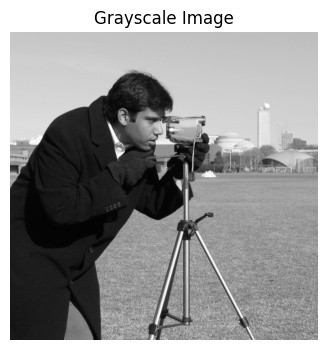

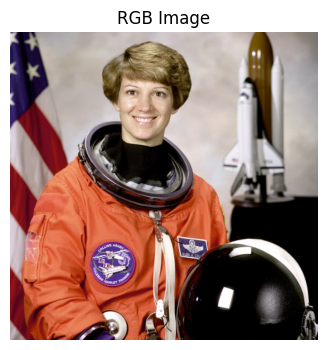

In [ ]:
# ------------------------------------------------------------
# Step 1: Load Sample Images
# ------------------------------------------------------------

# Load a grayscale image.
gray_image = data.camera()

# Load a color (RGB) image.
rgb_image = data.astronaut()


# ------------------------------------------------------------
# Step 2: Examine Image Dimensions
# ------------------------------------------------------------

print("GRAYSCALE IMAGE")
print("Shape:", gray_image.shape)
print("Number of dimensions:", gray_image.ndim)
print("Data type:", gray_image.dtype)

print("\nRGB IMAGE")
print("Shape:", rgb_image.shape)
print("Number of dimensions:", rgb_image.ndim)
print("Data type:", rgb_image.dtype)


# ------------------------------------------------------------
# Step 3: Display the Images
# ------------------------------------------------------------

show_image(gray_image, title="Grayscale Image", cmap="gray")
show_image(rgb_image, title="RGB Image")


In [ ]:
gray_image


### Activity 2.2: RGB Channels and Pixel Values

An RGB image consists of three color channels: **Red (R), Green (G), and Blue (B)**. Each channel is represented by a two-dimensional matrix containing the intensity values of that color.

For an image of height $H$ and width $W$, each channel has shape $(H,W)$, while the complete RGB image has shape $(H,W,3)$.

Each pixel at position $(i,j)$ is represented by a three-component vector:

$$
\mathbf{p}_{ij} =
\begin{bmatrix}
R_{ij} & G_{ij} & B_{ij}
\end{bmatrix}
$$

By extracting individual channels or selecting specific rows and columns, we can examine the numerical structure of an image.

**Practical objective:** Extract and visualize individual RGB channels, inspect pixel values, and select specific regions of an image using NumPy indexing and slicing.


In [ ]:
# ------------------------------------------------------------
# Step 1: Extract the RGB Channels
# ------------------------------------------------------------

R = rgb_image[:, :, 0]
G = rgb_image[:, :, 1]
B = rgb_image[:, :, 2]

print("Red channel shape:", R.shape)
print("Green channel shape:", G.shape)
print("Blue channel shape:", B.shape)


Red channel shape: (512, 512)
Green channel shape: (512, 512)
Blue channel shape: (512, 512)


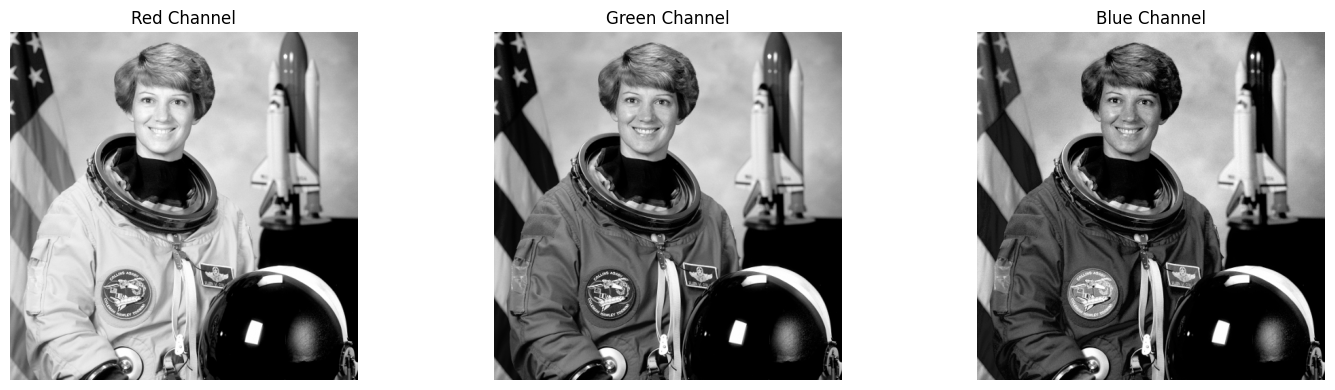

In [ ]:
# ------------------------------------------------------------
# Step 2: Display Individual Channels
# ------------------------------------------------------------

compare_images(
    [R, G, B],
    ["Red Channel", "Green Channel", "Blue Channel"],
    ["gray", "gray", "gray"]
)

In [ ]:
# ------------------------------------------------------------
# Step 3: Examine an Individual Pixel
# ------------------------------------------------------------

row, col = 100, 150

pixel = rgb_image[row, col]

print("\nPixel location:", (row, col))
print("RGB values:", pixel)

print("Red:", pixel[0])
print("Green:", pixel[1])
print("Blue:", pixel[2])


Pixel location: (100, 150)
RGB values: [193 182 178]
Red: 193
Green: 182
Blue: 178



Region shape: (100, 100, 3)


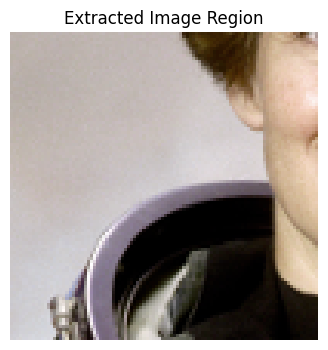

In [ ]:
# ------------------------------------------------------------
# Step 4: Extract a Small Image Region
# ------------------------------------------------------------

# Extract a 100 × 100 region.
region = rgb_image[100:200, 100:200]

print("\nRegion shape:", region.shape)

show_image(region, "Extracted Image Region")


### Activity 2.3: Image Brightness Using Scalar Operations

Image brightness can be adjusted by applying basic mathematical operations to pixel intensity values.

For an image represented by an array $I$, we can modify its brightness using:

**1. Scalar Multiplication**

$$
I_{\text{new}} = kI
$$

where $k$ is a scalar:

- $0 < k < 1$: Makes the image darker.
- $k = 1$: Leaves the image unchanged.
- $k > 1$: Makes the image brighter.

**2. Scalar Addition**

$$
I_{\text{new}} = I + c
$$

where $c$ is a constant added to every pixel value. Positive values increase brightness, while negative values decrease it.

For normalized images, pixel values should be restricted to $[0,1]$ using clipping to avoid invalid intensity values.

**Practical objective:** Apply scalar multiplication and addition to an RGB image and compare how these operations affect its brightness.


In [ ]:
# ------------------------------------------------------------
# Step 1: Normalize the Image
# ------------------------------------------------------------

# Convert pixel values from [0, 255] to [0, 1].
I = rgb_image.astype(float) / 255.0

print("Original pixel range:", rgb_image.min(), rgb_image.max())
print("Normalized pixel range:", I.min(), I.max())

Original pixel range: 0 255
Normalized pixel range: 0.0 1.0


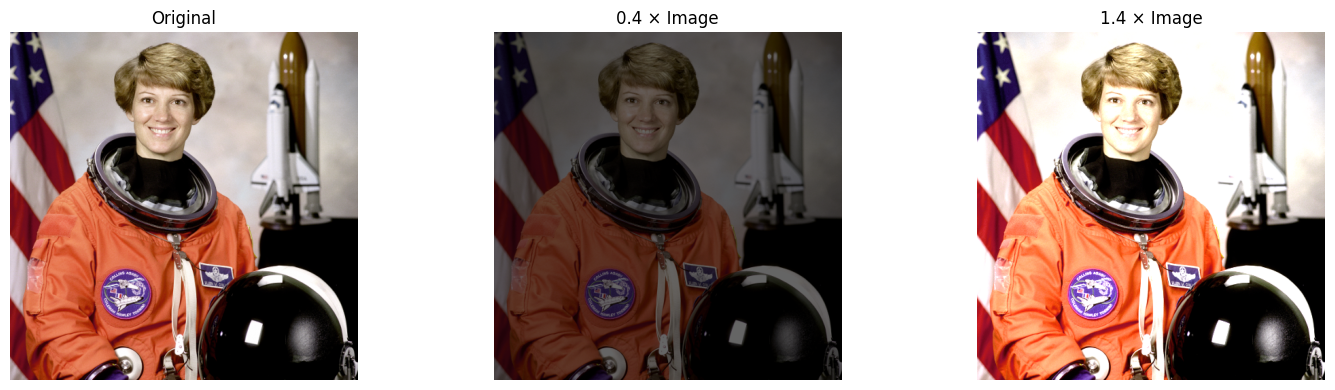

In [ ]:
# ------------------------------------------------------------
# Step 2: Scalar Multiplication
# ------------------------------------------------------------

# Darken the image.
darker = np.clip(0.4 * I, 0, 1)

# Brighten the image.
brighter = np.clip(1.4 * I, 0, 1)

compare_images(
    [I, darker, brighter],
    ["Original", "0.4 × Image", "1.4 × Image"]
)

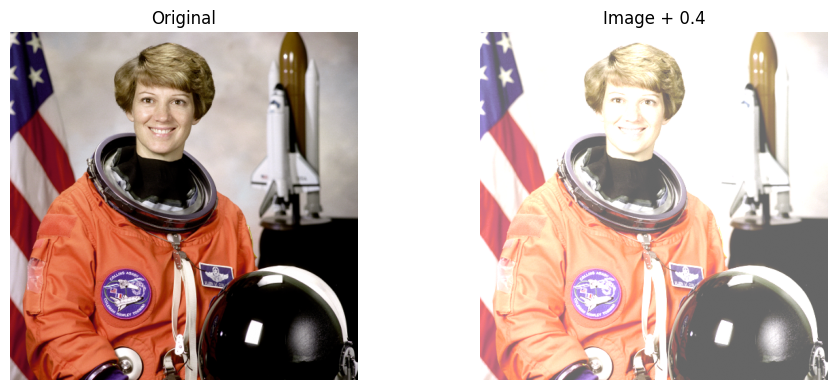

In [ ]:
# ------------------------------------------------------------
# Step 3: Scalar Addition
# ------------------------------------------------------------

# Add a constant to every pixel value.
shifted = np.clip(I + 0.4, 0, 1)

compare_images(
    [I, shifted],
    ["Original", "Image + 0.4"]
)


### Activity 2.4: Image Flipping and Blending

Images can be transformed and combined using basic matrix and array operations.

**1. Image Flipping**

Flipping an image horizontally reverses the order of its columns. For an image $I$ of width $W$, the flipped image is defined as:

$$
I_{\text{flip}}(i,j) = I(i,W-1-j)
$$

This operation changes the arrangement of pixels without changing their values.

**2. Image Blending**

Two images of the same shape can be combined using a weighted sum:

$$
I_{\text{blend}} = \alpha I_1 + (1-\alpha)I_2
$$

where:

- $I_1$ and $I_2$ are the two images.
- $\alpha \in [0,1]$ controls the contribution of each image.
- $\alpha=0.5$ gives equal weight to both images.

**Practical objective:** Flip an image horizontally and blend two images using weighted addition of their pixel values.


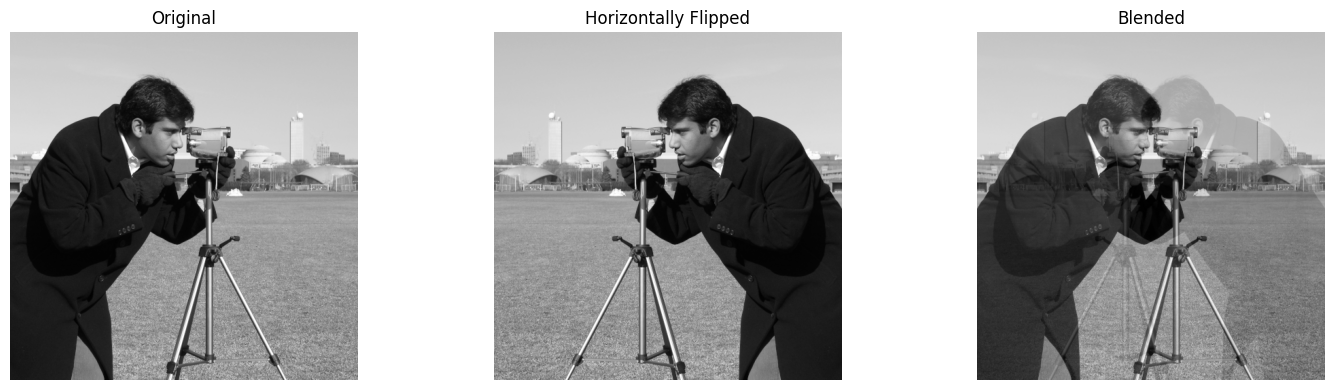

In [ ]:
# ------------------------------------------------------------
# Step 1: Prepare Two Images
# ------------------------------------------------------------

img1 = data.camera().astype(float) / 255.0

# Flip the image horizontally.
img2 = np.fliplr(img1)


# ------------------------------------------------------------
# Step 2: Blend the Images
# ------------------------------------------------------------

# Weighted combination of two images.
alpha = 0.8

blended = alpha * img1 + (1 - alpha) * img2


# ------------------------------------------------------------
# Step 3: Display the Results
# ------------------------------------------------------------

compare_images(
    [img1, img2, blended],
    ["Original", "Horizontally Flipped", "Blended"],
    ["gray", "gray", "gray"]
)


### Activity 2.5: RGB to Grayscale Conversion

A grayscale image contains a single intensity value for each pixel, while an RGB image contains three color values: Red (R), Green (G), and Blue (B).

We can convert an RGB image into grayscale by computing a **weighted sum** of its color channels:

$$
Y = 0.299R + 0.587G + 0.114B
$$

This can also be expressed as the **dot product** of two vectors:

$$
Y =
\begin{bmatrix}
R & G & B
\end{bmatrix}
\begin{bmatrix}
0.299\\
0.587\\
0.114
\end{bmatrix}
$$

The weights reflect the different contributions of red, green, and blue to perceived brightness.

For an entire RGB image, the same operation is applied to every pixel using NumPy matrix multiplication.

**Practical objective:** Convert an RGB image into grayscale using a weighted combination of color channels and demonstrate the application of the vector dot product in image processing.


In [ ]:
# ------------------------------------------------------------
# Step 1: Define Channel Weights
# ------------------------------------------------------------

weights = np.array([0.299, 0.587, 0.114])

print("Grayscale conversion weights:")
print(weights)


# ------------------------------------------------------------
# Step 2: Apply Weighted Combination
# ------------------------------------------------------------

# For each pixel, calculate a weighted sum of RGB values.
gray = rgb_image @ weights

print("\nRGB image shape:", rgb_image.shape)
print("Grayscale image shape:", gray.shape)


# ------------------------------------------------------------
# Step 3: Compare the Results
# ------------------------------------------------------------

compare_images(
    [rgb_image, gray],
    ["Original RGB Image", "Converted Grayscale Image"],
    [None, "gray"]
)



### 2.6 Image Transparency and the Alpha Channel

So far, we have represented color images using three channels: **Red (R), Green (G), and Blue (B)**. Each pixel contains three numerical values that determine its color.

However, images may also contain a fourth channel called the **alpha channel**, which controls transparency.

An image with four channels is called an **RGBA image**.

A pixel can therefore be represented as

$$
\mathbf{p} =
\begin{bmatrix}
R & G & B & \alpha
\end{bmatrix}
$$

where $\alpha$ represents the opacity of the pixel.

When alpha values are normalized to the interval $[0,1]$:

- $\alpha = 0$: Completely transparent.
- $\alpha = 1$: Completely opaque.
- $0 < \alpha < 1$: Partially transparent.

For an image of height $H$ and width $W$, its numerical representation changes from

$$
\text{RGB shape} = (H, W, 3)
$$

to

$$
\text{RGBA shape} = (H, W, 4).
$$

Thus, an RGBA image can be viewed as four matrices of size $H \times W$, where the first three matrices represent color intensities and the fourth represents transparency.

**Practical objective:** Add an alpha channel to an RGB image and observe how changing alpha values affects its transparency.


In [ ]:
# ------------------------------------------------------------
# Step 1: Load and Normalize the RGB Image
# ------------------------------------------------------------

rgb_image = data.astronaut()

# Convert pixel values to the interval [0, 1].
I = rgb_image.astype(float) / 255.0

height, width, channels = I.shape

print("RGB image shape:", I.shape)


RGB image shape: (512, 512, 3)


In [ ]:
# ------------------------------------------------------------
# Step 2: Create Alpha Channels
# ------------------------------------------------------------

# Completely opaque.
alpha_opaque = np.ones((height, width))

# Partially transparent.
alpha_half = np.full((height, width), 0.5)

# Completely transparent.
alpha_zero = np.zeros((height, width))


# ------------------------------------------------------------
# Step 3: Construct RGBA Images
# ------------------------------------------------------------

rgba_opaque = np.dstack((I, alpha_opaque))
rgba_half = np.dstack((I, alpha_half))
rgba_zero = np.dstack((I, alpha_zero))

print("RGBA image shape:", rgba_opaque.shape)

RGBA image shape: (512, 512, 4)


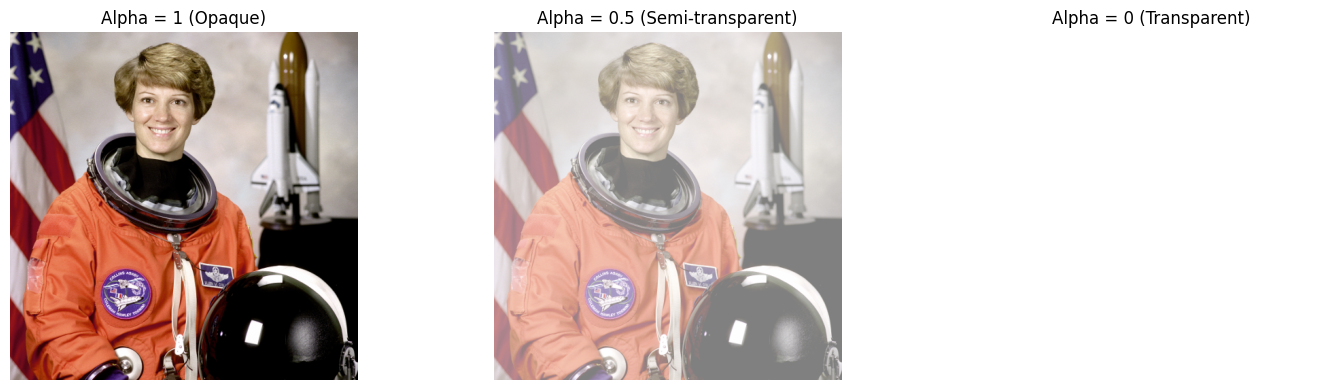

In [ ]:
# ------------------------------------------------------------
# Step 4: Display the Results
# ------------------------------------------------------------

# Use a dark background to make transparency visible.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

images = [rgba_opaque, rgba_half, rgba_zero]
titles = [
    "Alpha = 1 (Opaque)",
    "Alpha = 0.5 (Semi-transparent)",
    "Alpha = 0 (Transparent)"
]

for ax, image, title in zip(axes, images, titles):
    ax.set_facecolor("black")
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

Downloaded: images/foreground.png
Downloaded: images/background.png

Foreground shape: (500, 500, 3)
Background shape: (1626, 2382, 3)


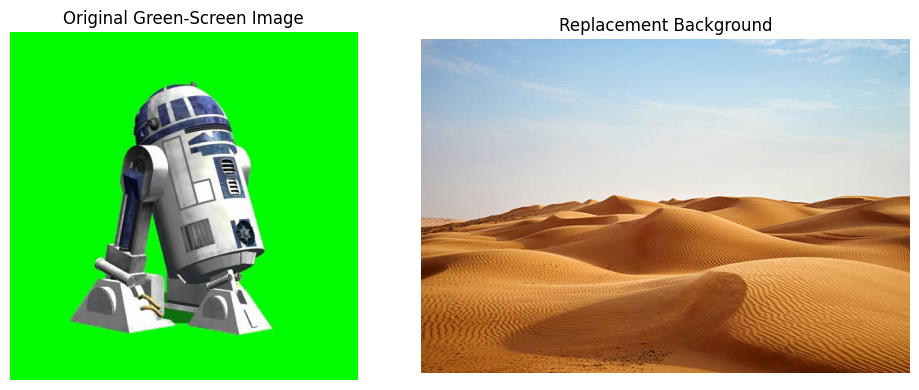

In [ ]:

#@title Activity 2.7: Download Real Images for Background Removal { display-mode: "form" }

from pathlib import Path
from urllib.request import urlretrieve
from PIL import Image

# ------------------------------------------------------------
# Step 1: Create a Working Directory
# ------------------------------------------------------------

image_dir = Path("images")
image_dir.mkdir(exist_ok=True)

# Public GitHub repository containing chroma-key examples.
base_url = (
    "https://raw.githubusercontent.com/"
    "RaulSanchezVazquez/chroma-key-composition/"
    "master/"
)

# ------------------------------------------------------------
# Step 2: Download the Images
# ------------------------------------------------------------

files = {
    "foreground.png": "R2D2.png",
    "background.png": "bg.png"
}

for local_name, remote_name in files.items():

    path = image_dir / local_name

    if not path.exists():
        urlretrieve(base_url + remote_name, path)

    print("Downloaded:", path)

# ------------------------------------------------------------
# Step 3: Load the Images as NumPy Arrays
# ------------------------------------------------------------

foreground_image = np.array(
    Image.open(image_dir / "foreground.png").convert("RGB")
)

background_image = np.array(
    Image.open(image_dir / "background.png").convert("RGB")
)

print("\nForeground shape:", foreground_image.shape)
print("Background shape:", background_image.shape)

# ------------------------------------------------------------
# Step 4: Display the Original Images
# ------------------------------------------------------------

compare_images(
    [foreground_image, background_image],
    ["Original Green-Screen Image", "Replacement Background"]
)



### 2.8 Removing the Green Background

Each pixel of a color image is represented by an RGB vector:

$$
\mathbf{p} =
\begin{bmatrix}
R\\G\\B
\end{bmatrix}
$$

To identify the green background, compare the green
component with the red and blue components.

A pixel is considered part of the green background when:

$$
G > R + t,\qquad G > B + t
$$

where $t$ is a threshold controlling how strongly green
must dominate the other channels.

We then construct a binary mask:

$$
M(i,j)=
\begin{cases}
0, & \text{background pixel}\\
1, & \text{foreground pixel}
\end{cases}
$$

This mask becomes the alpha channel of an RGBA image.


#### Why Is Green Commonly Used for Background Removal?

Green screens are widely used in filmmaking and video production because:

- **Color separation:** Green is relatively uncommon in human skin tones, making it easier to separate people from the background.
- **Camera sensitivity:** Digital cameras often capture more green samples, allowing cleaner background detection.
- **Easy processing:** A uniform green background can be identified using simple RGB pixel comparisons.

**Note:** Green is not mandatory. Blue or other colors can also be used, provided they are sufficiently different from the foreground. For example, blue screens are preferable when the subject wears green clothing.


**Objective:** Identify green pixels, construct a foreground
mask, and make the background transparent.




RGB shape: (500, 500, 3)
Alpha shape: (500, 500)
RGBA shape: (500, 500, 4)


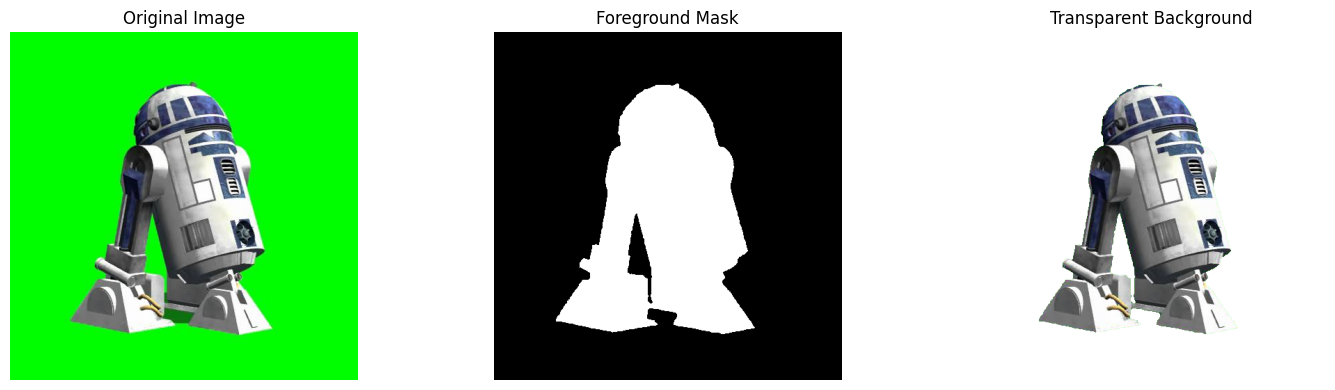

In [ ]:
# ------------------------------------------------------------
# Step 1: Extract RGB Channels
# ------------------------------------------------------------

# Convert to signed integers to avoid overflow.
I = foreground_image.astype(np.int16)

R = I[:, :, 0]
G = I[:, :, 1]
B = I[:, :, 2]

# ------------------------------------------------------------
# Step 2: Detect Green Background Pixels
# ------------------------------------------------------------

threshold = 35
minimum_green = 65

green_mask = (
    (G > R + threshold) &
    (G > B + threshold) &
    (G > minimum_green)
)

# Invert the background mask.
foreground_mask = ~green_mask

# ------------------------------------------------------------
# Step 3: Create an Alpha Channel
# ------------------------------------------------------------

alpha = foreground_mask.astype(float)

# Normalize RGB values.
foreground = foreground_image.astype(float) / 255.0

# Combine RGB and alpha.
rgba_image = np.dstack((foreground, alpha))

print("RGB shape:", foreground.shape)
print("Alpha shape:", alpha.shape)
print("RGBA shape:", rgba_image.shape)

# ------------------------------------------------------------
# Step 4: Display the Results
# ------------------------------------------------------------

compare_images(
    [foreground_image, foreground_mask, rgba_image],
    ["Original Image", "Foreground Mask", "Transparent Background"],
    [None, "gray", None]
)



### 2.9 Background Replacement Using Alpha Compositing

After constructing the alpha channel, we can place the
foreground object over a new background.

For each pixel, the resulting RGB vector is calculated as:

$$
\boxed{
C(i,j) = \alpha(i,j)F(i,j)
+ [1-\alpha(i,j)]B(i,j)
}
$$

where:

- $F(i,j)$ is the foreground RGB vector.
- $B(i,j)$ is the background RGB vector.
- $\alpha(i,j)$ is the foreground opacity.
- $C(i,j)$ is the resulting RGB vector.

This operation is a weighted combination of two images.

When $\alpha=1$, only the foreground is visible.
When $\alpha=0$, only the background is visible.

**Objective:** Replace the removed green background
with a real image using NumPy array operations.


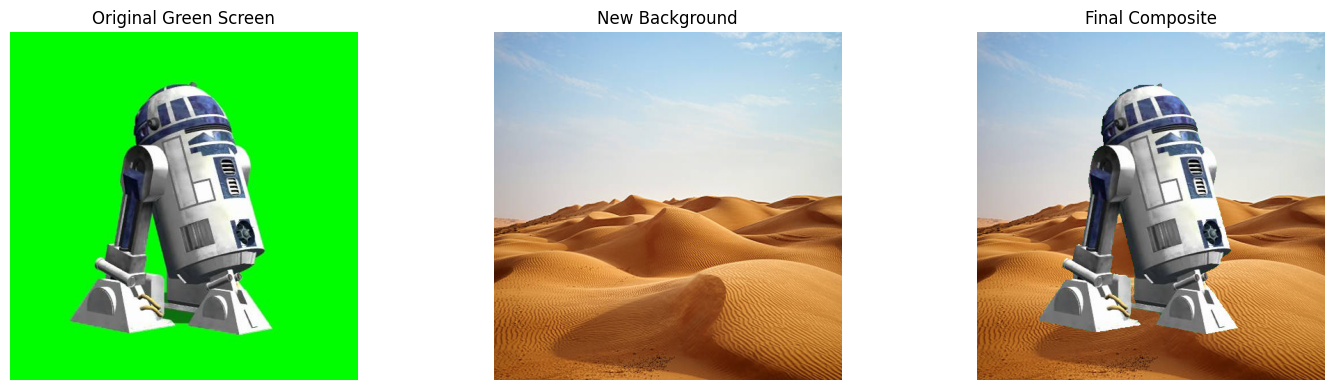

Saved: images/final_composite.png


In [ ]:
# ------------------------------------------------------------
# Step 1: Resize the Background
# ------------------------------------------------------------

height, width = foreground_image.shape[:2]

background_resized = np.array(
    Image.fromarray(background_image).resize(
        (width, height),
        Image.Resampling.LANCZOS
    )
)

# Normalize the background.
background = background_resized.astype(float) / 255.0

# ------------------------------------------------------------
# Step 2: Prepare the Alpha Mask
# ------------------------------------------------------------

# Expand alpha from (H, W) to (H, W, 1).
alpha_3d = alpha[:, :, np.newaxis]

# ------------------------------------------------------------
# Step 3: Combine Foreground and Background
# ------------------------------------------------------------

composite = (
    alpha_3d * foreground
    + (1 - alpha_3d) * background
)

# ------------------------------------------------------------
# Step 4: Display the Results
# ------------------------------------------------------------

compare_images(
    [foreground_image, background_resized, composite],
    ["Original Green Screen", "New Background", "Final Composite"]
)

# ------------------------------------------------------------
# Step 5: Save the Final Image
# ------------------------------------------------------------

output = (np.clip(composite, 0, 1) * 255).astype(np.uint8)

Image.fromarray(output).save(
    image_dir / "final_composite.png"
)

print("Saved:", image_dir / "final_composite.png")



## Exercise 2: Image Processing Using NumPy

### Objective

Apply basic linear algebra and NumPy array operations to manipulate digital images, create transparency masks, remove backgrounds, and combine images.

### Tasks

**Part A: Image Representation and Pixel Operations**

1. Load a color image and convert it into a NumPy array.
2. Display its shape, number of dimensions, and data type.
3. Extract and display the red, green, and blue channels separately.
4. Select a pixel and display its RGB values.
5. Create a darker version of the image using scalar multiplication.
6. Convert the RGB image into grayscale using a weighted combination of its color channels.

**Part B: Transparency and Background Removal**

7. Load a real green-screen image and a replacement background.
8. Extract the RGB channels and identify green-background pixels.
9. Construct a binary foreground mask.
10. Create an RGBA image using the foreground mask as its alpha channel.
11. Replace the green background using alpha compositing.
12. Display and compare the original image, foreground mask, and final composite.

### Questions

1. Why is a grayscale image represented by a 2D array while an RGB image requires a 3D array?
2. What is the difference between the shape of an RGB image and an RGBA image?
3. Does adding an alpha channel make the NumPy image array four-dimensional? Explain.
4. Why might a green-screen algorithm accidentally remove part of a person's clothing?
5. How does changing the background-detection threshold affect the resulting image?
6. Which linear algebra operations are involved in image brightness adjustment, grayscale conversion, and alpha compositing?


In [ ]:

#@title Exercise 2: Download the Required Images { display-mode: "form" }

from pathlib import Path
from urllib.request import urlretrieve
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Create a directory for exercise images.
image_dir = Path("exercise_images")
image_dir.mkdir(exist_ok=True)

# Image sources used in Activity 2.
base_url = (
    "https://raw.githubusercontent.com/"
    "RaulSanchezVazquez/chroma-key-composition/"
    "master/"
)

files = {
    "foreground.png": "R2D2.png",
    "background.png": "bg.png"
}

for local_name, remote_name in files.items():

    path = image_dir / local_name

    if not path.exists():
        urlretrieve(base_url + remote_name, path)

    print("Available:", path)

print("\nImages are ready for the exercise.")


Available: exercise_images/foreground.png
Available: exercise_images/background.png

Images are ready for the exercise.


In [ ]:
# ------------------------------------------------------------
# Task 1: Load the Foreground Image
# ------------------------------------------------------------

# TODO: Open foreground.png using PIL.
# TODO: Convert the image to RGB.
# TODO: Convert it into a NumPy array.

image_p = Image.open(image_dir / "foreground.png").convert("RGB")
image_rgb = image_p.convert("RGB")
image = np.array(image_rgb)


In [ ]:
# ------------------------------------------------------------
# Task 2: Examine the Image Representation
# ------------------------------------------------------------

# TODO: Print the shape of the image.
# TODO: Print the number of dimensions.
# TODO: Print the data type.
print("Shape",image.shape)
print("dim",image.ndim)
print("data type",image.dtype)

Shape (512, 512, 4)
dim 3
data type float64


In [ ]:
# ------------------------------------------------------------
# Task 3: Extract RGB Channels
# ------------------------------------------------------------

# TODO: Extract the red channel.
R = image[:,:,0]

# TODO: Extract the green channel.
G = image[:,:,1]

# TODO: Extract the blue channel.
B = image[:,:,2]

# TODO: Display the original image and three channels.
print("original\n",image)
print("red\n",R)
print("green\n",G)
print("blue\n",B)


original
 [[[0.604 0.576 0.592 0.   ]
  [0.427 0.404 0.486 0.   ]
  [0.247 0.227 0.4   0.   ]
  ...
  [0.498 0.471 0.451 0.   ]
  [0.471 0.459 0.416 0.   ]
  [0.49  0.467 0.431 0.   ]]

 [[0.694 0.671 0.671 0.   ]
  [0.565 0.553 0.561 0.   ]
  [0.443 0.447 0.486 0.   ]
  ...
  [0.498 0.463 0.439 0.   ]
  [0.486 0.451 0.424 0.   ]
  [0.475 0.455 0.412 0.   ]]

 [[0.788 0.761 0.757 0.   ]
  [0.714 0.698 0.686 0.   ]
  [0.659 0.647 0.643 0.   ]
  ...
  [0.502 0.471 0.459 0.   ]
  [0.494 0.455 0.439 0.   ]
  [0.486 0.447 0.427 0.   ]]

 ...

 [[0.729 0.667 0.69  0.   ]
  [0.729 0.667 0.694 0.   ]
  [0.718 0.659 0.667 0.   ]
  ...
  [0.    0.    0.    0.   ]
  [0.    0.    0.004 0.   ]
  [0.    0.    0.    0.   ]]

 [[0.718 0.663 0.667 0.   ]
  [0.714 0.655 0.671 0.   ]
  [0.725 0.643 0.69  0.   ]
  ...
  [0.    0.    0.004 0.   ]
  [0.004 0.004 0.004 0.   ]
  [0.    0.    0.    0.   ]]

 [[0.722 0.655 0.675 0.   ]
  [0.718 0.647 0.663 0.   ]
  [0.706 0.635 0.671 0.   ]
  ...
  [0.    0.   

In [ ]:
# ------------------------------------------------------------
# Task 4: Examine a Pixel
# ------------------------------------------------------------

# TODO: Select a pixel at row 100, column 100.
# TODO: Print its RGB values.

pixel = image[100,100]
#print(pixel)
print(pixel[0],pixel[1],pixel[2])

0.7333333333333333 0.6901960784313725 0.6627450980392157


In [ ]:
# ------------------------------------------------------------
# Task 5: Adjust Brightness
# ------------------------------------------------------------

# TODO: Convert image values to floating point.
# TODO: Normalize the image to [0, 1].
# TODO: Multiply all pixel values by 0.5.
# TODO: Display the original and darker images.

darker_float = image.astype(float)/255.0
darker_float *= 0.5
darker_image = np.uint8(darker_float*255).astype("uint8")
print("original\n",image)
print("darker\n",darker_image)

original
 [[[0.604 0.576 0.592 0.   ]
  [0.427 0.404 0.486 0.   ]
  [0.247 0.227 0.4   0.   ]
  ...
  [0.498 0.471 0.451 0.   ]
  [0.471 0.459 0.416 0.   ]
  [0.49  0.467 0.431 0.   ]]

 [[0.694 0.671 0.671 0.   ]
  [0.565 0.553 0.561 0.   ]
  [0.443 0.447 0.486 0.   ]
  ...
  [0.498 0.463 0.439 0.   ]
  [0.486 0.451 0.424 0.   ]
  [0.475 0.455 0.412 0.   ]]

 [[0.788 0.761 0.757 0.   ]
  [0.714 0.698 0.686 0.   ]
  [0.659 0.647 0.643 0.   ]
  ...
  [0.502 0.471 0.459 0.   ]
  [0.494 0.455 0.439 0.   ]
  [0.486 0.447 0.427 0.   ]]

 ...

 [[0.729 0.667 0.69  0.   ]
  [0.729 0.667 0.694 0.   ]
  [0.718 0.659 0.667 0.   ]
  ...
  [0.    0.    0.    0.   ]
  [0.    0.    0.004 0.   ]
  [0.    0.    0.    0.   ]]

 [[0.718 0.663 0.667 0.   ]
  [0.714 0.655 0.671 0.   ]
  [0.725 0.643 0.69  0.   ]
  ...
  [0.    0.    0.004 0.   ]
  [0.004 0.004 0.004 0.   ]
  [0.    0.    0.    0.   ]]

 [[0.722 0.655 0.675 0.   ]
  [0.718 0.647 0.663 0.   ]
  [0.706 0.635 0.671 0.   ]
  ...
  [0.    0.   

In [ ]:
# ------------------------------------------------------------
# Task 6: Convert RGB to Grayscale
# ------------------------------------------------------------

# Use the weights:
# Red   = 0.299
# Green = 0.587
# Blue  = 0.114

weights = np.array([0.299, 0.587, 0.114])

# TODO: Calculate the weighted combination of RGB channels.
# Hint: Use matrix multiplication with @.

image_rgb = image[:, :, :3] if image.ndim == 3 and image.shape[2] == 4 else image

gray_image = image_rgb @ weights

gray_image_uint8 = np.clip(gray_image, 0, 255).astype("uint8")




# TODO: Display the grayscale image.
print("original\n",image)
print("gray\n",gray_image)


Grayscale image shape: (512, 512)
original
 [[[0.604 0.576 0.592 0.   ]
  [0.427 0.404 0.486 0.   ]
  [0.247 0.227 0.4   0.   ]
  ...
  [0.498 0.471 0.451 0.   ]
  [0.471 0.459 0.416 0.   ]
  [0.49  0.467 0.431 0.   ]]

 [[0.694 0.671 0.671 0.   ]
  [0.565 0.553 0.561 0.   ]
  [0.443 0.447 0.486 0.   ]
  ...
  [0.498 0.463 0.439 0.   ]
  [0.486 0.451 0.424 0.   ]
  [0.475 0.455 0.412 0.   ]]

 [[0.788 0.761 0.757 0.   ]
  [0.714 0.698 0.686 0.   ]
  [0.659 0.647 0.643 0.   ]
  ...
  [0.502 0.471 0.459 0.   ]
  [0.494 0.455 0.439 0.   ]
  [0.486 0.447 0.427 0.   ]]

 ...

 [[0.729 0.667 0.69  0.   ]
  [0.729 0.667 0.694 0.   ]
  [0.718 0.659 0.667 0.   ]
  ...
  [0.    0.    0.    0.   ]
  [0.    0.    0.004 0.   ]
  [0.    0.    0.    0.   ]]

 [[0.718 0.663 0.667 0.   ]
  [0.714 0.655 0.671 0.   ]
  [0.725 0.643 0.69  0.   ]
  ...
  [0.    0.    0.004 0.   ]
  [0.004 0.004 0.004 0.   ]
  [0.    0.    0.    0.   ]]

 [[0.722 0.655 0.675 0.   ]
  [0.718 0.647 0.663 0.   ]
  [0.706 0.635

In [ ]:
# ------------------------------------------------------------
# Task 7: Load Foreground and Background Images
# ------------------------------------------------------------

# TODO: Load foreground.png as an RGB NumPy array.
foreground_image = np.array(
    Image.open(image_dir / "foreground.png").convert("RGB")
)

# TODO: Load background.png as an RGB NumPy array.
background_image = np.array(
    Image.open(image_dir / "background.png").convert("RGB")
)
# TODO: Display both images.



print("\nForeground shape:", foreground_image.shape)
print("Background shape:", background_image.shape)




Foreground shape: (500, 500, 3)
Background shape: (1626, 2382, 3)


In [ ]:
# ------------------------------------------------------------
# Task 8: Identify Green Pixels
# ------------------------------------------------------------

# TODO: Convert the foreground image to int16.
# This prevents overflow when adding thresholds.

I = for

# TODO: Extract the R, G, and B channels.
R = I[:, :, 0]
G = I[:,:,1]
B = I[:,:,2]

threshold = 35
minimum_green = 65

# TODO: Identify pixels satisfying:
# G > R + threshold
# G > B + threshold
# G > minimum_green

green_mask = (G > R + threshold) & (G > B + threshold) & (G > minimum_green)

In [ ]:
# ------------------------------------------------------------
# Task 9: Construct the Foreground Mask
# ------------------------------------------------------------

# TODO: Invert the green mask.
# Foreground pixels should be True.
# Background pixels should be False.

foreground_mask = ~green_mask


# TODO: Display the binary mask.
mask = foreground_mask
print("mask\n",mask)


mask
 [[False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]
 ...
 [False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]]


In [ ]:
# ------------------------------------------------------------
# Task 10: Create an RGBA Image
# ------------------------------------------------------------

# TODO: Normalize foreground RGB values to [0, 1].
foreground = foreground_image.astype(float) / 255.0

alpha = foreground_mask.astype(float)

# TODO: Convert the foreground mask to floating point.
alpha = foreground_mask.astype(float)

# TODO: Stack RGB and alpha to create an RGBA image.
rgba_image = np.dstack((foreground, alpha))


# TODO: Print the RGBA shape.
# TODO: Display the transparent image.
print("RGBA shape:", rgba_image.shape)
print("RGBA\n",rgba_image)

In [ ]:
# ------------------------------------------------------------
# Task 11: Replace the Background
# ------------------------------------------------------------

# TODO: Get the foreground height and width.

height = foreground_image.shape[0]
width = foreground_image.shape[1]

# TODO: Resize the background to match the foreground.
# Hint: Use PIL Image.resize().

background_pil = Image.fromarray(background_image)
background_resized_pil = background_pil.resize((width, height))
background_resized = np.array(background_resized_pil)

# TODO: Normalize background values to [0, 1].
background = background_resized.astype(float) / 255.0

# TODO: Expand alpha to shape (H, W, 1).
alpha_3d = alpha[:, :, np.newaxis]


# TODO: Apply alpha compositing:
#
# composite = alpha * foreground + (1 - alpha) * background

composite = alpha_3d * foreground + (1 - alpha_3d) * background

# TODO: Display the composite image.
print("composite\n",composite)


composite
 [[[0.624 0.671 0.757]
  [0.627 0.675 0.761]
  [0.627 0.675 0.761]
  ...
  [0.643 0.784 0.878]
  [0.627 0.769 0.863]
  [0.604 0.769 0.871]]

 [[0.608 0.663 0.753]
  [0.612 0.667 0.757]
  [0.612 0.667 0.757]
  ...
  [0.62  0.773 0.875]
  [0.608 0.761 0.859]
  [0.588 0.761 0.867]]

 [[0.596 0.659 0.753]
  [0.6   0.663 0.757]
  [0.604 0.667 0.761]
  ...
  [0.584 0.749 0.855]
  [0.576 0.745 0.847]
  [0.573 0.757 0.867]]

 ...

 [[0.616 0.341 0.082]
  [0.584 0.318 0.063]
  [0.545 0.282 0.043]
  ...
  [0.439 0.176 0.043]
  [0.486 0.227 0.063]
  [0.588 0.329 0.075]]

 [[0.62  0.333 0.059]
  [0.62  0.353 0.071]
  [0.596 0.333 0.067]
  ...
  [0.396 0.153 0.004]
  [0.376 0.133 0.008]
  [0.455 0.204 0.039]]

 [[0.612 0.325 0.055]
  [0.6   0.333 0.059]
  [0.576 0.314 0.051]
  ...
  [0.482 0.227 0.035]
  [0.42  0.165 0.012]
  [0.388 0.141 0.008]]]


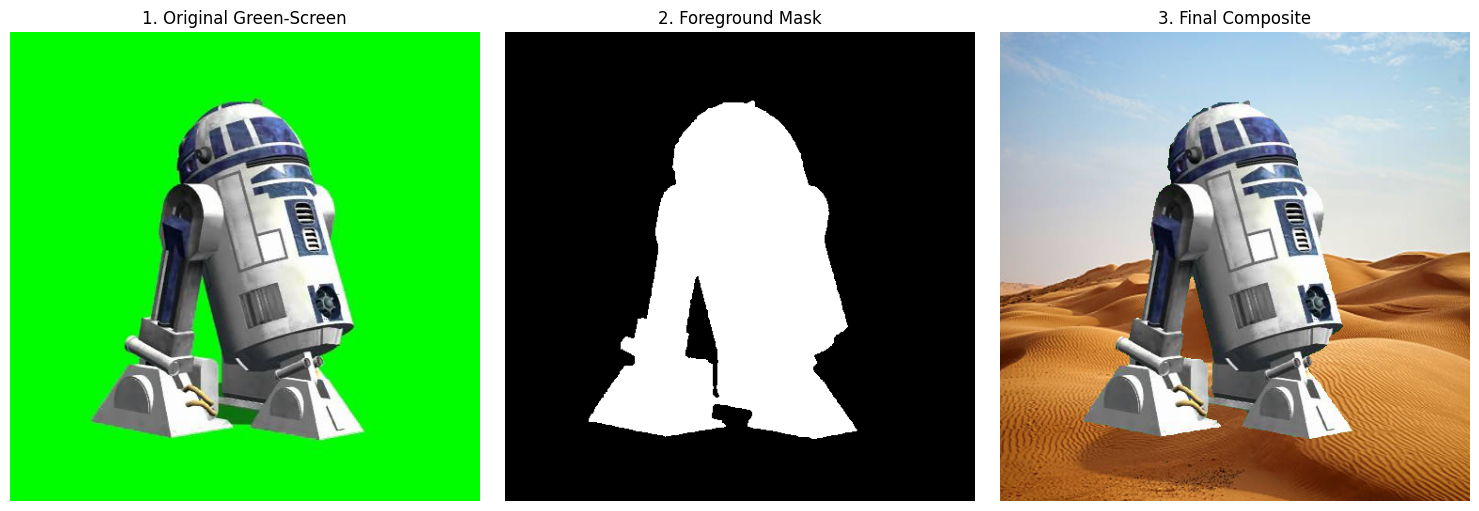

Final composite successfully saved to: exercise_images/final_composite.png


In [ ]:
# ------------------------------------------------------------
# Task 12: Display and Compare
# ------------------------------------------------------------

# TODO: Display:
# 1. Original green-screen image
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(Image.open(image_dir / "foreground.png"))
axes[0].set_title("1. Original Green-Screen")
axes[0].axis("off")
# 2. Foreground mask

axes[1].imshow(foreground_mask, cmap="gray")
axes[1].set_title("2. Foreground Mask")
axes[1].axis("off")

# 3. Final composite image
composite_uint8 = (np.clip(composite, 0, 1) * 255).astype(np.uint8)
composite_pil = Image.fromarray(composite_uint8)
axes[2].imshow(composite_uint8)
axes[2].set_title("3. Final Composite")
axes[2].axis("off")
plt.tight_layout()
plt.show()

# TODO: Save the final composite as a PNG file.
output_path = image_dir / "final_composite.png"
composite_pil.save(output_path)
print(f"Final composite successfully saved to: {output_path}")


### Optional Challenge: Background Detection Threshold

Repeat the background removal process using different threshold values:

$$
t \in \{10, 20, 40, 60, 80\}.
$$

For each threshold:

1. Construct the foreground mask.
2. Replace the background.
3. Display the resulting image.
4. Compare the quality of background removal.

**Discussion:** Which threshold produces the best result? Explain why very small or very large thresholds may incorrectly classify image pixels.


In [ ]:
# thresholds = [10,20,40,60,80]
# minimum_green = 65

# for i,t in enumerate(thresholds):
#     green_mask = (G > R + t) & (G > B + t) & (G > minimum_green)
#     foreground_mask = ~green_mask

#     alpha_test = foreground_mask.astype(float)
#     alpha_test_d = np.expand_dims(alpha_test,axis=-1)
#     comp_test = alpha_test_d * foreground + (1 - alpha_test_d) *background
#     comp_test_uint8 = (np.clip(comp_test, 0, 1) * 255).astype(np.uint8)

#     fig, axes = plt.subplots(1, 3, figsize=(15, 5))


